In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


# Load dailyActivity directly using the path variable
daily_activity = pd.read_csv("dailyActivity_merged.csv")
daily_activity.head()

,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories
0,1503960366,3/25/2016,11004,7.11,7.11,0.0,2.57,0.46,4.07,0.0,33,12,205,804,1819
1,1503960366,3/26/2016,17609,11.55,11.55,0.0,6.92,0.73,3.91,0.0,89,17,274,588,2154
2,1503960366,3/27/2016,12736,8.53,8.53,0.0,4.66,0.16,3.71,0.0,56,5,268,605,1944
3,1503960366,3/28/2016,13231,8.93,8.93,0.0,3.19,0.79,4.95,0.0,39,20,224,1080,1932
4,1503960366,3/29/2016,12041,7.85,7.85,0.0,2.16,1.09,4.61,0.0,28,28,243,763,1886


In [23]:
# Process(Data cleaning)
print("Dataset Shape:", daily_activity.shape)
daily_activity.info()

Dataset Shape: (457, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 457 entries, 0 to 456
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Id                        457 non-null    int64  
 1   ActivityDate              457 non-null    object 
 2   TotalSteps                457 non-null    int64  
 3   TotalDistance             457 non-null    float64
 4   TrackerDistance           457 non-null    float64
 5   LoggedActivitiesDistance  457 non-null    float64
 6   VeryActiveDistance        457 non-null    float64
 7   ModeratelyActiveDistance  457 non-null    float64
 8   LightActiveDistance       457 non-null    float64
 9   SedentaryActiveDistance   457 non-null    float64
 10  VeryActiveMinutes         457 non-null    int64  
 11  FairlyActiveMinutes       457 non-null    int64  
 12  LightlyActiveMinutes      457 non-null    int64  
 13  SedentaryMinutes          457 non-null  

In [24]:
# Process(Data cleaning)
print("Missing Values")
print(daily_activity.isnull().sum())

print("Duplicates")
print(daily_activity.duplicated().sum())


Missing Values
Id                          0
ActivityDate                0
TotalSteps                  0
TotalDistance               0
TrackerDistance             0
LoggedActivitiesDistance    0
VeryActiveDistance          0
ModeratelyActiveDistance    0
LightActiveDistance         0
SedentaryActiveDistance     0
VeryActiveMinutes           0
FairlyActiveMinutes         0
LightlyActiveMinutes        0
SedentaryMinutes            0
Calories                    0
dtype: int64
Duplicates
0


In [25]:
# Process(Data cleaning)
print("Number of unique IDs: ", daily_activity['Id'].nunique())

Number of unique IDs:  35


In [40]:
, legend=False# Process(Data cleaning)
#Fix Data Types (Date Formatting)

# Convert ActivityDate from string to datetime
daily_activity['ActivityDate'] = pd.to_datetime(daily_activity['ActivityDate'])

daily_activity['Day Of Week'] = daily_activity['ActivityDate'].dt.day_name()

In [27]:
# Process(Data cleaning)

sleep_day = pd.read_csv('sleepDay_merged.csv')
print(sleep_day.shape)
print("Unique IDs: ", sleep_day['Id'].nunique())
print("Duplicates: ", sleep_day.duplicated().sum())
sleep_day.info()
sleep_day.head()

(413, 5)
Unique IDs:  24
Duplicates:  3
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 413 entries, 0 to 412
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   Id                  413 non-null    int64 
 1   SleepDay            413 non-null    object
 2   TotalSleepRecords   413 non-null    int64 
 3   TotalMinutesAsleep  413 non-null    int64 
 4   TotalTimeInBed      413 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 16.3+ KB


,Id,SleepDay,TotalSleepRecords,TotalMinutesAsleep,TotalTimeInBed
0,1503960366,4/12/2016 12:00:00 AM,1,327,346
1,1503960366,4/13/2016 12:00:00 AM,2,384,407
2,1503960366,4/15/2016 12:00:00 AM,1,412,442
3,1503960366,4/16/2016 12:00:00 AM,2,340,367
4,1503960366,4/17/2016 12:00:00 AM,1,700,712


In [28]:
# Process(Data cleaning)

sleep_day['SleepDay'] = pd.to_datetime(sleep_day['SleepDay'], format='mixed')
sleep_day.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 413 entries, 0 to 412
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Id                  413 non-null    int64         
 1   SleepDay            413 non-null    datetime64[ns]
 2   TotalSleepRecords   413 non-null    int64         
 3   TotalMinutesAsleep  413 non-null    int64         
 4   TotalTimeInBed      413 non-null    int64         
dtypes: datetime64[ns](1), int64(4)
memory usage: 16.3 KB


/tmp/ipykernel_648/3878495176.py:3: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  sleep_day['SleepDay'] = pd.to_datetime(sleep_day['SleepDay'])


In [29]:
# Process(Data cleaning)

sleep_day = sleep_day.drop_duplicates()

print("Duplicates after cleaning: ", sleep_day.duplicated().sum())

Duplicates after cleaning:  0


In [30]:
#Analyze
# Rename 'SleepDay' to 'ActivityDate' in the sleep dataset
sleep_day = sleep_day.rename(columns={'SleepDay': 'ActivityDate'})

In [31]:
#Analyze
merged_data = pd.merge(daily_activity, sleep_day, on=['Id', 'ActivityDate'], how='inner')

print('Merged Dataset: ', merged_data.shape)
merged_data.head()

Merged Dataset:  (12, 19)


,Id,ActivityDate,TotalSteps,TotalDistance,TrackerDistance,LoggedActivitiesDistance,VeryActiveDistance,ModeratelyActiveDistance,LightActiveDistance,SedentaryActiveDistance,VeryActiveMinutes,FairlyActiveMinutes,LightlyActiveMinutes,SedentaryMinutes,Calories,Day Of Week,TotalSleepRecords,TotalMinutesAsleep,TotalTimeInBed
0,1503960366,2016-04-12,224,0.14,0.14,0.0,0.0,0.0,0.13,0.0,0,0,9,32,50,Tuesday,1,327,346
1,1927972279,2016-04-12,24,0.02,0.02,0.0,0.0,0.0,0.02,0.0,0,0,3,161,942,Tuesday,3,750,775
2,2026352035,2016-04-12,1019,0.63,0.63,0.0,0.0,0.0,0.63,0.0,0,0,64,223,600,Tuesday,1,503,546
3,3977333714,2016-04-12,759,0.57,0.57,0.0,0.0,0.0,0.57,0.0,0,0,17,187,182,Tuesday,1,274,469
4,4020332650,2016-04-12,8,0.01,0.01,0.0,0.0,0.0,0.01,0.0,0,0,1,321,446,Tuesday,1,501,541


In [32]:
#Analyze
#Calculate the average, minimum, and maximum
merged_data[['TotalSteps', 'Calories', 'TotalMinutesAsleep', 'TotalTimeInBed']].describe()

,TotalSteps,Calories,TotalMinutesAsleep,TotalTimeInBed
count,12.000000,12.000000,12.000000,12.000000
mean,1278.083333,645.833333,443.833333,483.166667
std,1892.471662,498.710306,122.832357,113.515584
min,0.000000,0.000000,274.000000,346.000000
25%,23.000000,380.000000,359.000000,426.000000
50%,354.000000,629.000000,435.000000,466.500000
75%,1575.750000,788.000000,501.500000,529.000000
max,5893.000000,1882.000000,750.000000,775.000000


In [33]:
#Analyze
#Time spend sitting/lying down vs time being active

activity_levels = daily_activity[['SedentaryMinutes','LightlyActiveMinutes','FairlyActiveMinutes', 'VeryActiveMinutes']].mean()
print('<<Average Minutes for eac Activity Level>>')
print(activity_levels)

<<Average Minutes for eac Activity Level>>
SedentaryMinutes        995.282276
LightlyActiveMinutes    170.070022
FairlyActiveMinutes      13.070022
VeryActiveMinutes        16.623632
dtype: float64


In [34]:
#Analyze
#Track activity by day of the week

day_of_week_steps = daily_activity.groupby('Day Of Week')['TotalSteps'].mean().sort_values(ascending=False)
print('<<Average steps by Day of Week>>')
print(day_of_week_steps)

<<Average steps by Day of Week>>
Day Of Week
Wednesday    7510.708333
Monday       7118.588235
Saturday     7089.773333
Thursday     6847.083333
Friday       6737.561644
Sunday       6058.013889
Tuesday      4914.917808
Name: TotalSteps, dtype: float64


/tmp/ipykernel_648/2937908598.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=day_of_week_steps, x='Day Of Week', y='AverageSteps', palette='viridis')


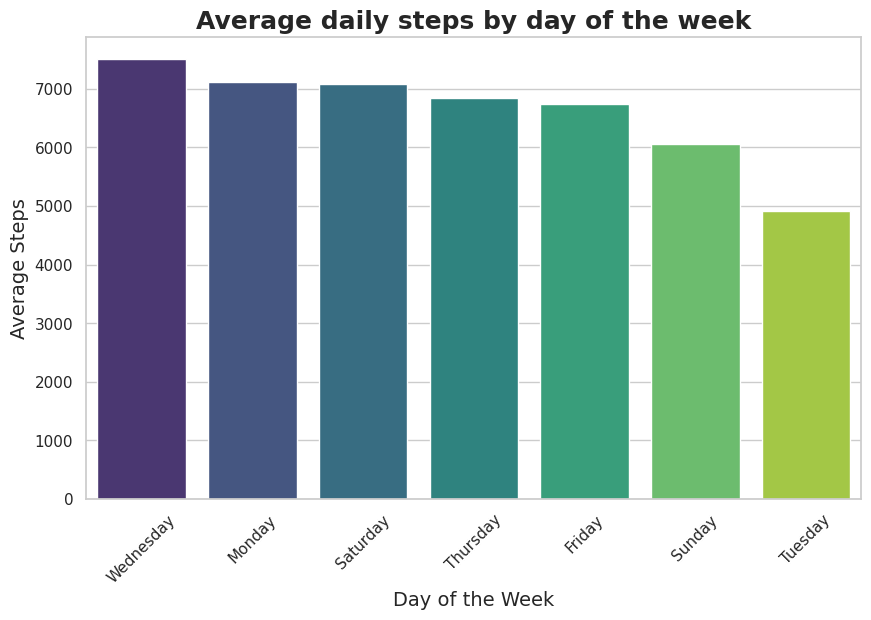

In [35]:
#Share
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

# Force the data into a clean DataFrame (Fixes the TypeError)
# Create a bar chart mapping the Days to the Average Steps
day_of_week_steps = daily_activity.groupby('Day Of Week')['TotalSteps'].mean().reset_index()
day_of_week_steps = day_of_week_steps.rename(columns={'TotalSteps': 'AverageSteps'})
day_of_week_steps = day_of_week_steps.sort_values(by='AverageSteps', ascending=False)

#Create the bar chart
sns.barplot(data=day_of_week_steps, x='Day Of Week', y='AverageSteps',hue='Day Of Week', palette='viridis', legend=False)

plt.title("Average daily steps by day of the week", fontsize=18, fontweight='bold')
plt.xlabel("Day of the Week", fontsize=14)
plt.ylabel("Average Steps", fontsize=14)
plt.xticks(rotation=45)

plt.show()

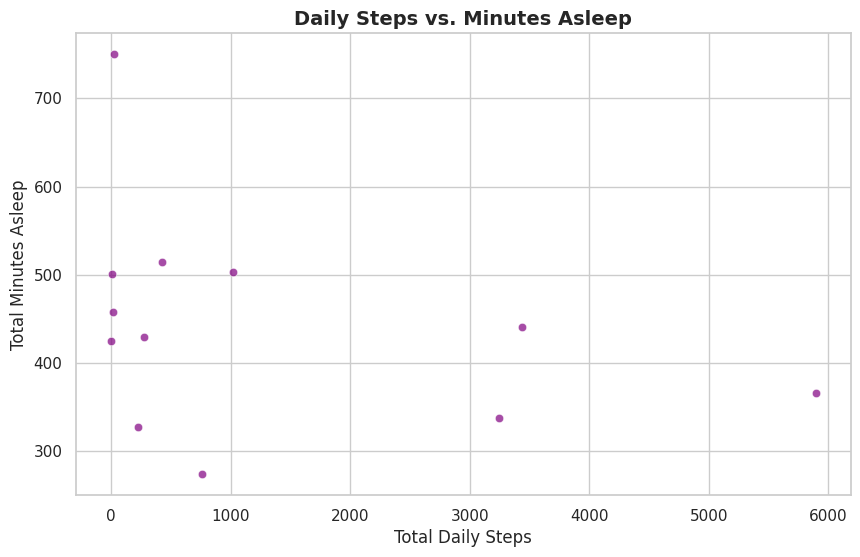

In [36]:
#share
#Set the size and style of the chart

plt.figure(figsize=(10,6))
sns.set_theme(style="whitegrid")

#Create a scatter plot mapping Total Steps to Minutes Asleep
sns.scatterplot(data=merged_data, x='TotalSteps', y='TotalMinutesAsleep', color='purple', alpha=0.7)

#Add clear titles and labels
plt.title("Daily Steps vs. Minutes Asleep", fontsize=14, fontweight='bold')
plt.xlabel("Total Daily Steps", fontsize=12)
plt.ylabel("Total Minutes Asleep", fontsize=12)

plt.show()

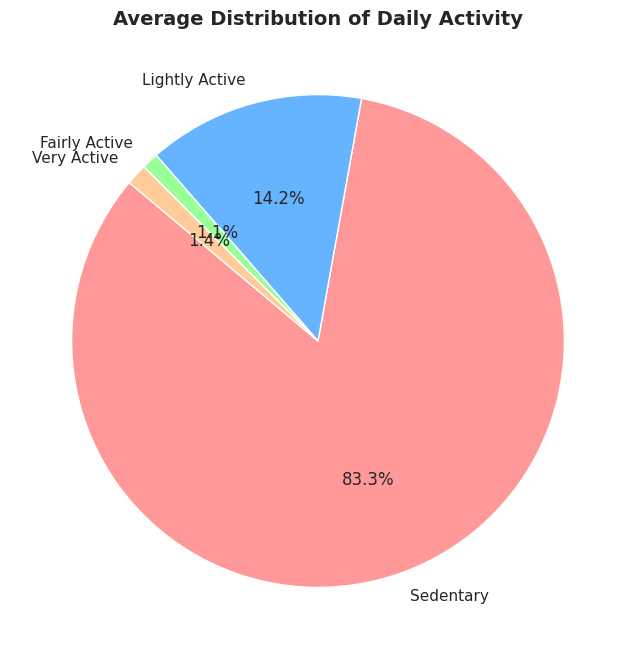

In [37]:
#share
#The Sedentary Reality

activity_levels = daily_activity[['SedentaryMinutes', 'LightlyActiveMinutes', 'FairlyActiveMinutes', 'VeryActiveMinutes']].mean()

#Set up the pie chart labels and colors
plt.figure(figsize=(8,8))
labels = ['Sedentary', 'Lightly Active', 'Fairly Active', 'Very Active']
colors = ['#ff9999', '#66b3ff', '#99ff99', '#ffcc99']

#Create the pie chart
plt.pie(activity_levels, labels=labels, colors=colors, autopct='%1.1f%%', startangle=140)

plt.title("Average Distribution of Daily Activity", fontsize=14, fontweight='bold')

plt.show()

/tmp/ipykernel_648/3822455313.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=user_counts, x='Tracking Type', y='Unique Users', palette='Set2')


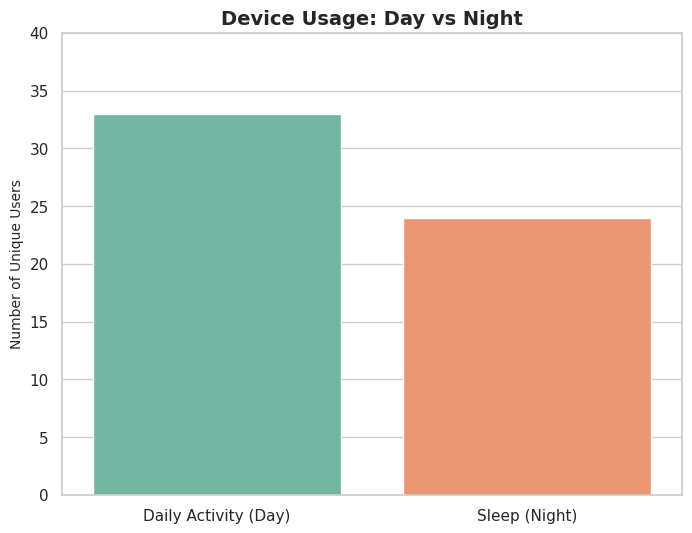

In [38]:
#share
plt.figure(figsize=(8,6))
sns.set_theme(style="whitegrid")

#creating a simple table
user_counts = pd.DataFrame({
    'Tracking Type': ['Daily Activity (Day)', 'Sleep (Night)'],
    'Unique Users': [33,24]
})

#creating the bar chart
sns.barplot(data=user_counts, x='Tracking Type', y='Unique Users',hue='Tracking Type', palette='Set2', legend=False)

plt.title("Device Usage: Day vs Night", fontsize=14, fontweight='bold')
plt.ylabel("Number of Unique Users", fontsize=10)
plt.xlabel("")
plt.ylim(0,40)

plt.show()